# 14-5. 시드 민감도와 동점 후보

`model_selection` 모듈의 리샘플링 난수 시드를 바꿔도 모델 선정이 같은지 확인한다. 변수 6개를 시드 5개(42, 1, 2, 3, 4)로 모두 계산했다(자체 구간은 난수를 쓰지 않아 시드와 무관하다).

- **비교 기준**: 선정 규칙은 12시리즈와 같다(CRPS 1등의 +-10% 이내 중 커버리지가 90%에 가장 가까운 것)
- **시드**: 모든 변수, 모델, (d, D)가 같은 시드를 써서 같은 난수로 비교한다(모델 간 비교에서 난수 잡음이 상쇄된다)

## 1. 시드별 선정

In [1]:
import sys
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
sys.path.insert(0, "../..")
from model_selection import selection as S
from model_selection.variables import GOLD

SEEDS = [42, 1, 2, 3, 4]
TAB = {}
for sd in SEEDS:
    S.SEED = sd
    for code, cfg in GOLD.items():
        TAB[(sd, code)] = S.table(S.run_grid(cfg))               # 시드마다 캐시(model_selection/cache)에 저장된 결과를 읽는다
lab = lambda s: f"{s[0]}·({s[1]},{s[2]})·{s[3]}·{s[4]}"
print("변수", len(GOLD), "개 x 시드", len(SEEDS), "개 =", len(TAB), "개 결과를 읽었다")

변수 6 개 x 시드 5 개 = 30 개 결과를 읽었다


In [2]:
SEL = {}
for (sd, code), t in TAB.items():
    f = t[np.isfinite(t["CRPS"])]
    c = f[f["CRPS"] <= f["CRPS"].min() * 1.10]
    c = c.iloc[np.argsort((c["커버리지(%)"] - 90).abs().values, kind="stable")]
    SEL[(sd, code)] = tuple(c.index[0])
out = pd.DataFrame({sd: {code: lab(SEL[(sd, code)]) for code in GOLD} for sd in SEEDS})
out["모든 시드에서 같음"] = pd.Series({code: len({SEL[(sd, code)] for sd in SEEDS}) == 1 for code in GOLD})
with pd.option_context("display.width", 250, "display.max_columns", 20):
    display(out)

,42,1,2,3,4,모든 시드에서 같음
X1_l1,"GARCH·(0,0)·원·리샘플링","SV·(0,0)·원·리샘플링","GARCH·(0,0)·원·리샘플링","GARCH·(0,0)·원·리샘플링","GARCH·(0,0)·원·리샘플링",False
X2,"AR단독·(0,0)·원·자체","AR단독·(0,0)·원·자체","AR단독·(0,0)·원·자체","AR단독·(0,0)·원·자체","AR단독·(0,0)·원·자체",True
X3_l1,"GARCH·(1,0)·원·리샘플링","GARCH·(1,0)·원·리샘플링","GARCH·(1,0)·원·리샘플링","GARCH·(1,0)·원·리샘플링","GARCH·(1,0)·원·리샘플링",True
X4,"GARCH·(0,0)·원·리샘플링","GARCH·(0,0)·원·리샘플링","GARCH·(0,0)·원·리샘플링","GARCH·(0,0)·원·리샘플링","GARCH·(0,0)·원·리샘플링",True
X5_l1,"GARCH·(0,0)·로그·자체","GARCH·(0,0)·로그·자체","GARCH·(0,0)·로그·자체","GARCH·(0,0)·로그·자체","GARCH·(0,0)·로그·자체",True
X6_l1,"SV·(1,0)·원·자체","SV·(1,0)·원·자체","SV·(1,0)·원·자체","SV·(1,0)·원·자체","AR단독·(1,1)·로그·리샘플링",False


## 2. 시드 42 선정 조합의 점수가 시드에 따라 흔들리는 정도

In [3]:
rows = []
for code in GOLD:
    sel = SEL[(42, code)]
    c = [TAB[(sd, code)].loc[sel, "CRPS"] for sd in SEEDS]
    v = [TAB[(sd, code)].loc[sel, "커버리지(%)"] for sd in SEEDS]
    rows.append({"변수": code, "시드 42 선정": lab(sel), "CRPS 최소": min(c), "CRPS 최대": max(c), "CRPS 범위(%)": (max(c) / min(c) - 1) * 100,
                 "커버리지 최소": min(v), "커버리지 최대": max(v)})
with pd.option_context("display.float_format", "{:,.4f}".format, "display.width", 250):
    display(pd.DataFrame(rows).set_index("변수"))

,시드 42 선정,CRPS 최소,CRPS 최대,CRPS 범위(%),커버리지 최소,커버리지 최대
변수,,,,,,
X1_l1,"GARCH·(0,0)·원·리샘플링",0.7453,0.7584,1.7579,80.9524,82.1429
X2,"AR단독·(0,0)·원·자체",0.5248,0.5248,0.0000,78.4091,78.4091
X3_l1,"GARCH·(1,0)·원·리샘플링",0.6203,0.6294,1.4671,84.0909,85.2273
X4,"GARCH·(0,0)·원·리샘플링",0.5861,0.5918,0.9759,85.2273,87.5000
X5_l1,"GARCH·(0,0)·로그·자체",0.7116,0.7116,0.0000,86.9048,86.9048
X6_l1,"SV·(1,0)·원·자체",0.2724,0.2724,0.0000,90.0000,90.0000


## 3. X1: 동점 후보 두 개

In [4]:
a, b = ("GARCH", 0, 0, "원", "리샘플링"), ("SV", 0, 0, "원", "리샘플링")
rows = []
for sd in SEEDS:
    t = TAB[(sd, "X1_l1")]
    rows.append({"시드": sd, "GARCH CRPS": t.loc[a, "CRPS"], "GARCH 커버리지": t.loc[a, "커버리지(%)"], "SV CRPS": t.loc[b, "CRPS"], "SV 커버리지": t.loc[b, "커버리지(%)"],
                 "CRPS 1등": t["CRPS"][np.isfinite(t["CRPS"])].min(), "선정": lab(SEL[(sd, "X1_l1")])})
with pd.option_context("display.float_format", "{:,.4f}".format, "display.width", 250):
    display(pd.DataFrame(rows).set_index("시드"))

,GARCH CRPS,GARCH 커버리지,SV CRPS,SV 커버리지,CRPS 1등,선정
시드,,,,,,
42,0.7453,82.1429,0.7455,80.9524,0.7285,"GARCH·(0,0)·원·리샘플링"
1,0.7515,80.9524,0.7499,82.1429,0.7285,"SV·(0,0)·원·리샘플링"
2,0.7515,80.9524,0.7521,79.7619,0.7285,"GARCH·(0,0)·원·리샘플링"
3,0.7552,82.1429,0.7570,80.9524,0.7285,"GARCH·(0,0)·원·리샘플링"
4,0.7584,80.9524,0.7566,79.7619,0.7285,"GARCH·(0,0)·원·리샘플링"


## 4. 어느 후보를 쓰느냐에 따른 앱 시나리오 값의 차이

In [5]:
S.SEED = 42
cfg = GOLD["X1_l1"]
res = S.run_grid(cfg)
sd_y = S.load(cfg)[1].std()
fa = S.forecast_table(res, a).set_index(["예측시점", "분기"])
fb = S.forecast_table(res, b).set_index(["예측시점", "분기"])
d = (fa - fb).drop(columns=["h", "q50"]).abs() / sd_y * 100
last = d.loc["2026Q1"]
display(pd.DataFrame({"모든 예측시점 평균": d.mean(), "2026Q1 시점 평균": last.mean(), "최대": d.max()}).round(1))
print("표의 값은 GARCH와 SV의 시나리오 값(하한, 점예측, 상한) 차이를 변수 표준편차로 나눈 %다")

,모든 예측시점 평균,2026Q1 시점 평균,최대
하한,30.7,56.8,156.3
중앙값,15.3,24.2,96.3
상한,45.4,16.3,264.9


표의 값은 GARCH와 SV의 시나리오 값(하한, 점예측, 상한) 차이를 변수 표준편차로 나눈 %다


## 5. 그래프: 성능과 구간 폭은 비슷하고 시나리오 값은 조금 다르다

X1의 두 후보(GARCH, SV)를 비교한다. ①은 시드별 성능, ②는 예측시점별 구간 폭, ③은 가장 최근 시점의 시나리오 값이다.

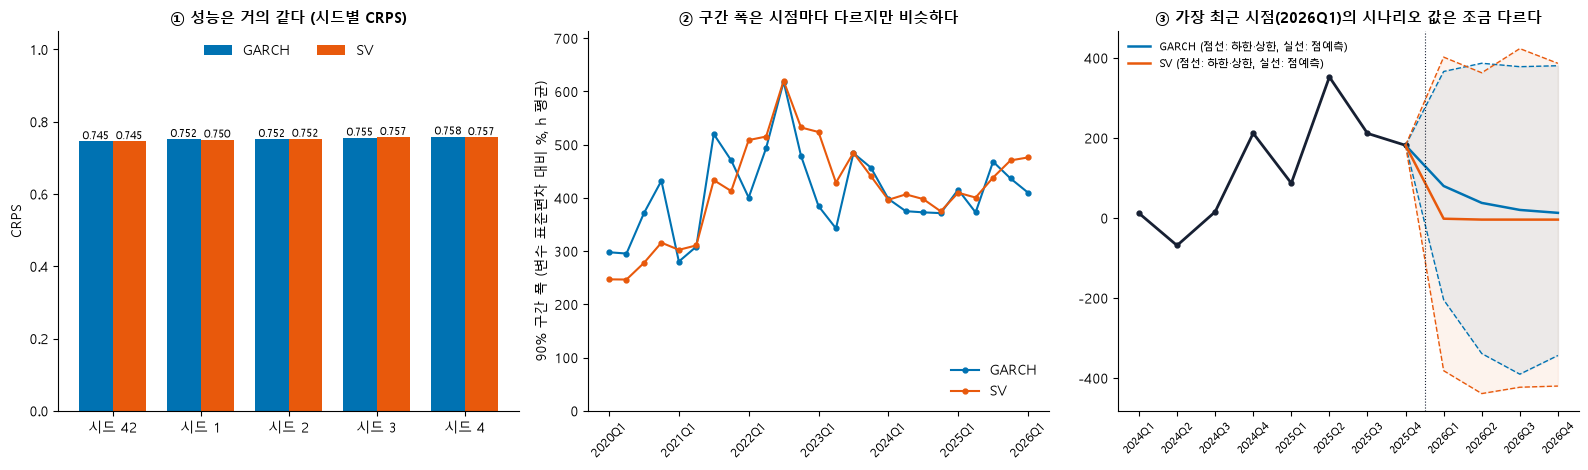

In [6]:
import matplotlib.pyplot as plt
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False
BLUE, ORG, DARK = "#0072B2", "#E8590C", "#172033"
q_in, y_in = S.load(cfg)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.8))
x = np.arange(len(SEEDS))
ga = [TAB[(sd, "X1_l1")].loc[a, "CRPS"] for sd in SEEDS]
sv = [TAB[(sd, "X1_l1")].loc[b, "CRPS"] for sd in SEEDS]
ax[0].bar(x - 0.19, ga, 0.38, color=BLUE, label="GARCH")
ax[0].bar(x + 0.19, sv, 0.38, color=ORG, label="SV")
for xi, g_, s_ in zip(x, ga, sv):
    ax[0].text(xi - 0.19, g_, f"{g_:.3f}", ha="center", va="bottom", fontsize=8)
    ax[0].text(xi + 0.19, s_, f"{s_:.3f}", ha="center", va="bottom", fontsize=8)
ax[0].set_xticks(x)
ax[0].set_xticklabels([f"시드 {sd}" for sd in SEEDS])
ax[0].set_ylim(0, 1.05)
ax[0].set_ylabel("CRPS")
ax[0].set_title("① 성능은 거의 같다 (시드별 CRPS)", fontsize=11, fontweight="bold")
ax[0].legend(frameon=False, loc="upper center", ncol=2)
wa = ((fa["상한"] - fa["하한"]) / sd_y * 100).groupby(level=0).mean()
wb = ((fb["상한"] - fb["하한"]) / sd_y * 100).groupby(level=0).mean()
ax[1].plot(range(len(wa)), wa.values, color=BLUE, marker="o", markersize=3.5, label="GARCH")
ax[1].plot(range(len(wb)), wb.values, color=ORG, marker="o", markersize=3.5, label="SV")
ax[1].set_xticks(range(0, len(wa), 4))
ax[1].set_xticklabels(wa.index[::4], rotation=45, fontsize=8.5)
ax[1].set_ylim(0, max(wa.max(), wb.max()) * 1.15)
ax[1].set_ylabel("90% 구간 폭 (변수 표준편차 대비 %, h 평균)")
ax[1].set_title("② 구간 폭은 시점마다 다르지만 비슷하다", fontsize=11, fontweight="bold")
ax[1].legend(frameon=False, loc="lower right")
n_h = 8
ax[2].plot(np.arange(-n_h, 0), y_in[-n_h:], color=DARK, linewidth=2, marker="o", markersize=3.5)
fx = np.arange(0, 4)
for t_, col, nm in ((fa.loc["2026Q1"], BLUE, "GARCH"), (fb.loc["2026Q1"], ORG, "SV")):
    ax[2].fill_between(np.r_[-1, fx], np.r_[y_in[-1], t_["하한"]], np.r_[y_in[-1], t_["상한"]], color=col, alpha=0.07)
    for k_ in ("하한", "상한"):
        ax[2].plot(np.r_[-1, fx], np.r_[y_in[-1], t_[k_]], color=col, linewidth=1.0, linestyle="--")
    ax[2].plot(np.r_[-1, fx], np.r_[y_in[-1], t_["중앙값"]], color=col, linewidth=1.8, label=f"{nm} (점선: 하한·상한, 실선: 점예측)")
ax[2].axvline(-0.5, color=DARK, linestyle=":", linewidth=0.8)
lab_q = list(q_in[-n_h:]) + list(fa.loc["2026Q1"].index)
ax[2].set_xticks(np.arange(-n_h, 4))
ax[2].set_xticklabels(lab_q, rotation=45, fontsize=8)
ax[2].set_title("③ 가장 최근 시점(2026Q1)의 시나리오 값은 조금 다르다", fontsize=11, fontweight="bold")
ax[2].legend(frameon=False, fontsize=8, loc="upper left")
for a_ in ax:
    a_.spines["top"].set_visible(False)
    a_.spines["right"].set_visible(False)
fig.tight_layout()
plt.show()

## 결론과 상의할 점

**시드 5개(42, 1, 2, 3, 4)로 본 선정의 안정성**
- 변수 6개 중 5개는 모든 시드에서 선정이 같다. 자체 구간 변수(X2, X5, X6)는 점수가 시드와 무관하고, 리샘플링 변수(X3, X4, X1)는 CRPS가 1.0~1.8% 범위로 흔들린다.
- **X1만 선정이 갈린다**: 시드 5개 중 4개는 GARCH·(0,0)·원·리샘플링, 시드 1만 SV·(0,0)·원·리샘플링이다. 두 후보는 CRPS 차이가 0.001~0.002이고 커버리지도 79.8~82.1%에서 엇갈리는 사실상 동점이라, 난수가 어느 쪽을 뽑을지 정한다.

**모델이 달라도 성능과 구간 폭은 비슷하다**
- 두 후보의 CRPS와 커버리지(79.8~82.1%)가 비슷하다. 구간 폭도 예측시점마다 조금씩 다르지만(평균 45%p 차이, 변수 표준편차의 410%와 415%) 전체적으로는 비슷하다.
- 시나리오 값(하한, 점예측, 상한)은 모든 예측시점 평균으로 변수 표준편차의 15%, 31%, 45%만큼 다르고 가장 최근(2026Q1) 시점은 하한이 57%다. 커버리지가 비슷해서 어느 쪽을 써도 큰 문제는 없다고 본다. 이 차이가 TVP 금 가격으로 얼마나 전달되는지는 계산하지 않았다.

**상의가 필요한 것: 동점 후보를 어떻게 정할 것인가**
1. 지금 규칙(CRPS 1등 +-10% 이내 중 커버리지가 90%에 가장 가까운 것)을 유지하고, 시드를 하나(42)로 고정해 결과를 안정시킨다(X1는 GARCH로 바뀐다).
2. 동점 규칙을 추가한다. 예: 1등과 CRPS 차이가 아주 작은 후보 중 더 단순한 모델을 고른다. 이 규칙이 다른 변수 선정을 바꾸지 않는지 확인이 필요하다.
3. 시드와 선정 방식을 그대로 두고 시드 변경만 보류한다.